<a href="https://colab.research.google.com/github/d4nv/ml-campus_data_project-colab/blob/main/CampusWalk_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Campus Walk ML Project

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import pandas as pd

## Load the Data


I loaded the campus data set using pd.read_csv using " skiprows = 4 " because the first 4 lines of the data were a title block, not data I then checked the rows and shapes and the columns names

In [5]:
df = pd.read_csv("/content/drive/MyDrive/CampusWalkDataset_TemplateIDs(Sheet1).csv", skiprows=4)



## Data Exploration

In [6]:
df.head()          # first 5 rows


,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,...,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes,Unnamed: 23,Unnamed: 24,Unnamed: 25,Unnamed: 26
0,R26_001,9/22/2026,L01 MainEntrance,Partly cloudy,16,Quiet,Low,Human voices,Traffic,Wind,...,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees,NaN,NaN,NaN,NaN,NaN
1,R26_001,9/22/2026,L02 LibraryGreen,Sunny,16,Moderate,Low,Traffic,Human voices,Wind,...,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass,NaN,NaN,NaN,NaN,NaN
2,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Partly cloudy,16,Quiet,Low,Construction,Traffic,Wind,...,Positive wellbeing,Easy,Mostly calm,No change,Very quiet,NaN,NaN,NaN,NaN,NaN
3,R26_001,9/22/2026,L08 AccessRoadNearSportsCentre,Partly cloudy,16,Moderate,Low,Human voices,Human voices,Wind,...,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind,NaN,NaN,NaN,NaN,NaN
4,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Sunny,16,Moderate,Low,Traffic,Other,Wind,...,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area,NaN,NaN,NaN,NaN,NaN


## Data Analysis


In [7]:
df.shape           # (rows, columns)

(994, 27)

In [8]:
df.columns         # column names

Index(['recorder_id', 'date', 'location', 'weather', 'temperature_c',
       'sound level', 'foot_traffic', 'primary_sound_type_urban',
       'other_sound_type_urban', 'primary_sound_type_nature',
       'other_sound_type_nature', 'insects_count', 'birds_count',
       'trees_presence', 'native_or_wild_plant_presence',
       'ornnamental_or_planted_plant_presence', 'moss_or_lichen_presence',
       'wellbeing_rating', 'ease_rating', 'stress_rating',
       'nature_connection_experience_rating', 'most_notable_nature_element',
       'other_notes', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25',
       'Unnamed: 26'],
      dtype='object')

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 994 entries, 0 to 993
Data columns (total 27 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   recorder_id                            199 non-null    object 
 1   date                                   135 non-null    object 
 2   location                               135 non-null    object 
 3   weather                                135 non-null    object 
 4   temperature_c                          135 non-null    object 
 5   sound level                            135 non-null    object 
 6   foot_traffic                           135 non-null    object 
 7   primary_sound_type_urban               135 non-null    object 
 8   other_sound_type_urban                 132 non-null    object 
 9   primary_sound_type_nature              135 non-null    object 
 10  other_sound_type_nature                133 non-null    object 
 11  insect

In [10]:
df.describe()

,insects_count,birds_count,Unnamed: 23,Unnamed: 24,Unnamed: 25,Unnamed: 26
count,135.000000,135.000000,0.0,0.0,0.0,0.0
mean,2.733333,1.992593,NaN,NaN,NaN,NaN
std,5.106624,2.789897,NaN,NaN,NaN,NaN
min,0.000000,0.000000,NaN,NaN,NaN,NaN
25%,0.000000,0.000000,NaN,NaN,NaN,NaN
50%,1.000000,1.000000,NaN,NaN,NaN,NaN
75%,3.000000,3.000000,NaN,NaN,NaN,NaN
max,31.000000,20.000000,NaN,NaN,NaN,NaN


# Data Cleaning

 I removed rows with no location, because they are blank entries, not real observations. I also dropped the "Unnamed" columns, which were empty columns created by the Excel file. I reset the index so the rows are numbered cleanly again. The shape went from [before] to [after].

In [11]:
print("Before:", df.shape)
df = df.dropna(subset=['location'])
df = df.loc[:, ~df.columns.str.startswith('Unnamed')]
df = df.reset_index(drop=True)
print("After:", df.shape)


Before: (994, 27)
After: (135, 23)


 I removed stray spaces and made the capitalisation consistent in all text columns. Without this, values like "cloudy" and "Cloudy " would be counted as different categories. [Example you noticed]

In [12]:
# remove stray spaces and fix capitalisation
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].astype(str).str.strip()
    df[col] = df[col].replace('nan', pd.NA)

df['weather'] = df['weather'].str.capitalize()
df['foot_traffic'] = df['foot_traffic'].str.capitalize()

# fix typos
df['ease_rating'] = df['ease_rating'].replace({'Vey easy': 'Very easy', 'Slighly uneasy': 'Slightly uneasy'})
df['nature_connection_experience_rating'] = df['nature_connection_experience_rating'].replace({'same': 'No change'})

## Cleaning temperature

 Some values were written as 17C so i removed the C and coverted the column to numbers charts need numeric values not text.

In [13]:
df['temperature_c'] = df['temperature_c'].astype(str).str.replace('C', '', regex=False)
df['temperature_c'] = pd.to_numeric(df['temperature_c'], errors='coerce')

In [14]:
print(df['temperature_c'].dtype)
print(df['temperature_c'].head())

float64
0    16.0
1    16.0
2    16.0
3    16.0
4    16.0
Name: temperature_c, dtype: float64


I counted the missing values in each column to decide how to handle them.

In [15]:
df.isnull().sum()

,0
recorder_id,0
date,0
location,0
weather,0
temperature_c,0
sound level,0
foot_traffic,0
primary_sound_type_urban,0
other_sound_type_urban,3
primary_sound_type_nature,0


## Filling in missing values
For the plant, tree, moss and other-sound columns, a blank means nothing was observed, so I filled them with "None" instead of deleting the rows. Deleting them would have thrown away useful data from an already small dataset.

In [16]:
# blank = nothing observed, so label it "None"
none_cols = ['trees_presence', 'native_or_wild_plant_presence',
             'ornnamental_or_planted_plant_presence', 'moss_or_lichen_presence',
             'other_sound_type_urban', 'other_sound_type_nature']
df[none_cols] = df[none_cols].fillna('None')

# free-text columns we won't use in the model
df['most_notable_nature_element'] = df['most_notable_nature_element'].fillna('Not recorded')
df['other_notes'] = df['other_notes'].fillna('No notes')

df.isnull().sum().sum()   # should print 0

np.int64(0)

In [17]:
print(df[none_cols].isnull().sum())

trees_presence                           0
native_or_wild_plant_presence            0
ornnamental_or_planted_plant_presence    0
moss_or_lichen_presence                  0
other_sound_type_urban                   0
other_sound_type_nature                  0
dtype: int64


## Converting ratings to numbers

 I converted the text ratings (wellbeing, ease, stress, nature connection) to numbers from 1 to 5, because machine learning models need numeric input. This is ordinal encoding, since the ratings have a natural order. One limitation is that the gaps between categories may not be equal, for example "Neutral" to "Positive wellbeing" may not be the same step as "Positve wellbeing" to "Very positive wellbeing".

In [18]:
wellbeing_map = {'Very low wellbeing': 1, 'Low wellbeing': 2, 'Neutral': 3,
                 'Positive wellbeing': 4, 'Very positive wellbeing': 5}
ease_map = {'Very uneasy': 1, 'Slightly uneasy': 2, 'Neutral': 3,
            'Easy': 4, 'Very easy': 5}
stress_map = {'Very stressful': 1, 'Stressful': 2, 'Neutral': 3,
              'Mostly calm': 4, 'Very calm': 5}
nature_map = {'Less connected': 1, 'No change': 2,
              'A little more connected': 3, 'Much more connected': 4}

df['wellbeing_num'] = df['wellbeing_rating'].map(wellbeing_map)
df['ease_num'] = df['ease_rating'].map(ease_map)
df['stress_num'] = df['stress_rating'].map(stress_map)
df['nature_num'] = df['nature_connection_experience_rating'].map(nature_map)

df[['wellbeing_num', 'ease_num', 'stress_num', 'nature_num']].isnull().sum()

,0
wellbeing_num,0
ease_num,0
stress_num,0
nature_num,0


In [19]:
print("--- Mapping check ---")
print(df[['wellbeing_rating', 'wellbeing_num']].drop_duplicates())

--- Mapping check ---
           wellbeing_rating  wellbeing_num
0        Positive wellbeing              4
6                   Neutral              3
9   Very positive wellbeing              5
22       Very low wellbeing              1
23            Low wellbeing              2


# Data Visualisation


## How calm people felt at each location

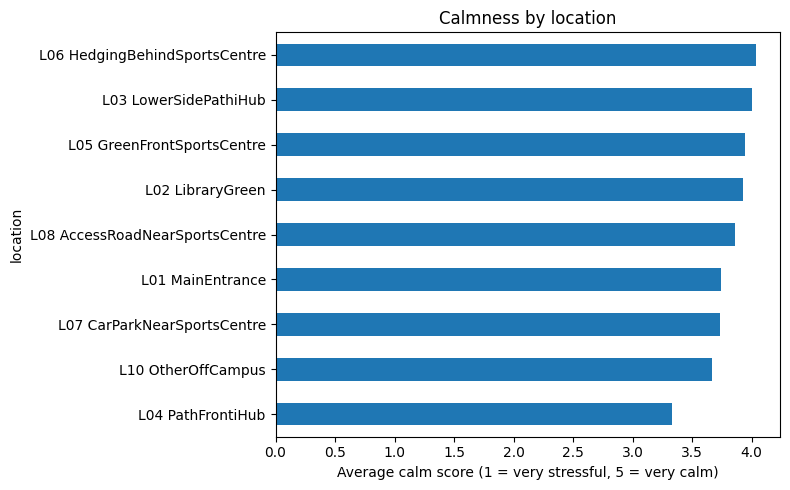

In [20]:
import matplotlib.pyplot as plt

avg = df.groupby('location')['stress_num'].mean().sort_values()
avg.plot(kind='barh', figsize=(8, 5))
plt.xlabel('Average calm score (1 = very stressful, 5 = very calm)')
plt.title('Calmness by location')
plt.tight_layout()
plt.show()

## Calm score by sound level

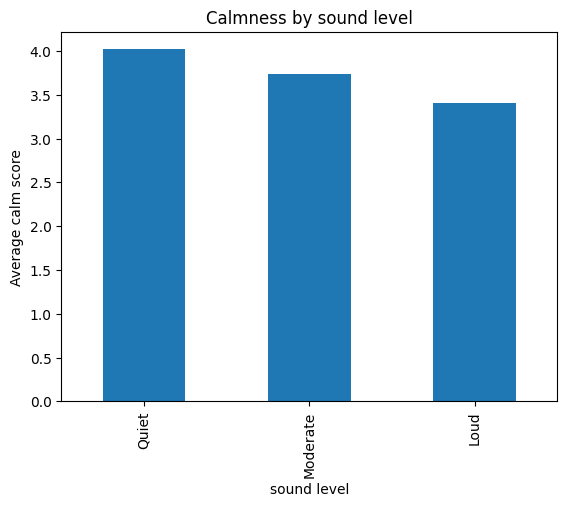

In [21]:
df.groupby('sound level')['stress_num'].mean().reindex(['Quiet', 'Moderate', 'Loud']).plot(kind='bar')
plt.ylabel('Average calm score')
plt.title('Calmness by sound level')
plt.show()

## Correlation

## Do more birds mean more nature connection

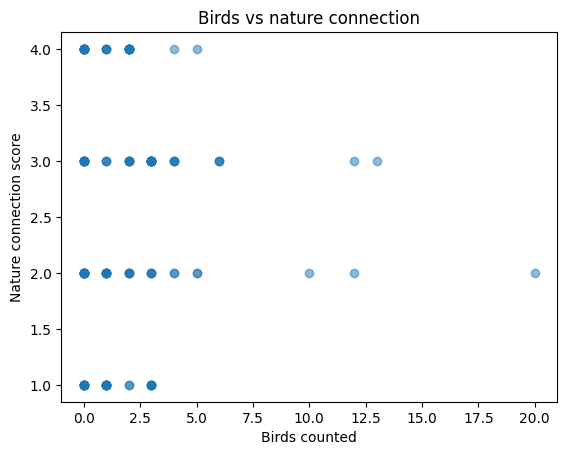

In [36]:
plt.scatter(df['birds_count'], df['nature_num'], alpha=0.5)
plt.xlabel('Birds counted')
plt.ylabel('Nature connection score')
plt.title('Birds vs nature connection')
plt.show()

In [37]:
r = df['birds_count'].corr(df['nature_num'])
print("Correlation (birds vs nature):", round(r, 2))

Correlation (birds vs nature): 0.01


The correlation is 0.01 so amount of birds people saw or heard had 0 correlation to the connection with nature


##Correlation heat map

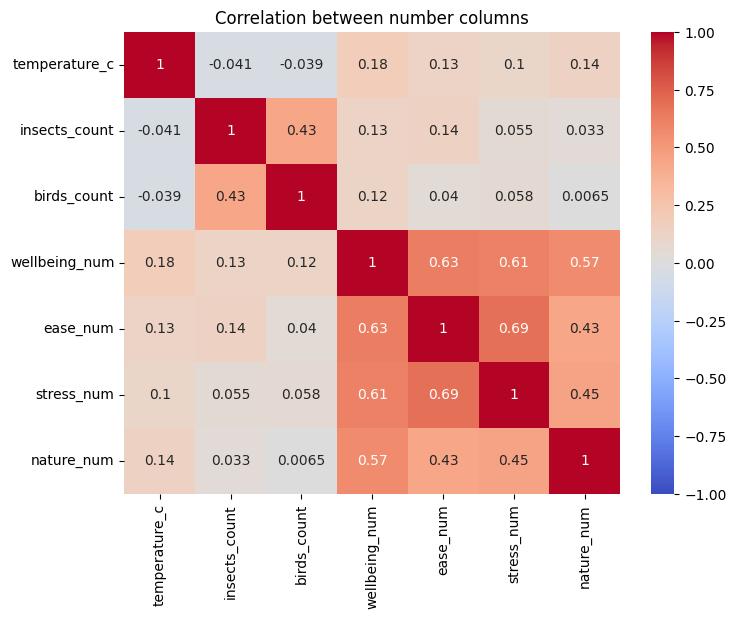

In [27]:

import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))
sns.heatmap(num_cols.corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation between number columns')
plt.show()

The strongest correlations are between the feeling ratings (ease and stress 0.69, wellbeing and ease 0.63). Birds and nature stay near 0. Temperature has almost no link to the other columns.

# Data Scaling

In [32]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaled = scaler.fit_transform(num_cols)
print(scaled.shape)
print(scaled[:3])

(135, 7)
[[-4.83561966e-01 -5.37245979e-01 -3.57106127e-01  3.74970109e-01
  -7.04597820e-01 -2.10473022e+00 -1.48902470e+00]
 [-4.83561966e-01 -5.37245979e-01  2.66497110e-03  3.74970109e-01
  -7.04597820e-01 -9.44980915e-01  4.25435630e-01]
 [-4.83561966e-01  1.42828809e+00  6.47854474e+00  3.74970109e-01
   3.88743625e-01  2.14768390e-01 -5.31794537e-01]]


I scaled the number columns so big counts do not drown out the 1 to 5 ratings.

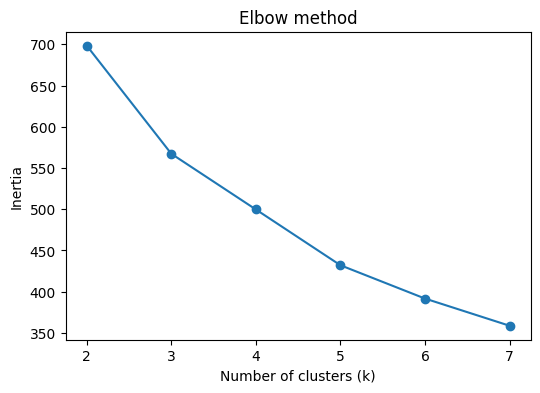

In [33]:
from sklearn.cluster import KMeans

inertias = []
ks = range(2, 8)

for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(list(ks), inertias, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow method')
plt.show()

The line bends around 3 clusters, so I used k = 3.

In [34]:
km = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = km.fit_predict(scaled)
df['cluster'] = labels
print(df['cluster'].value_counts().sort_index())

cluster
0    49
1    78
2     8
Name: count, dtype: int64


Most walks land in cluster 1; cluster 2 is a small group of 8.

In [35]:
print(df.groupby('cluster')[list(num_cols.columns)].mean().round(2))

         temperature_c  insects_count  birds_count  wellbeing_num  ease_num  \
cluster                                                                       
0                16.46            2.2         1.35           2.92      2.86   
1                16.85            1.5         1.68           4.12      4.08   
2                15.88           18.0         9.00           4.25      4.25   

         stress_num  nature_num  
cluster                          
0              3.00        1.73  
1              4.29        3.05  
2              4.12        2.75  


I sorted the walks into 3 groups. Group 0 felt worse on average. Group 1 felt better and has most of the walks. Group 2 is only a few walks, but those walks had way more insects and birds. The code only gave me group numbers, so I named them by looking at the averages.